Matplotlib Session 10 – Annotations, Legends & Highlighting

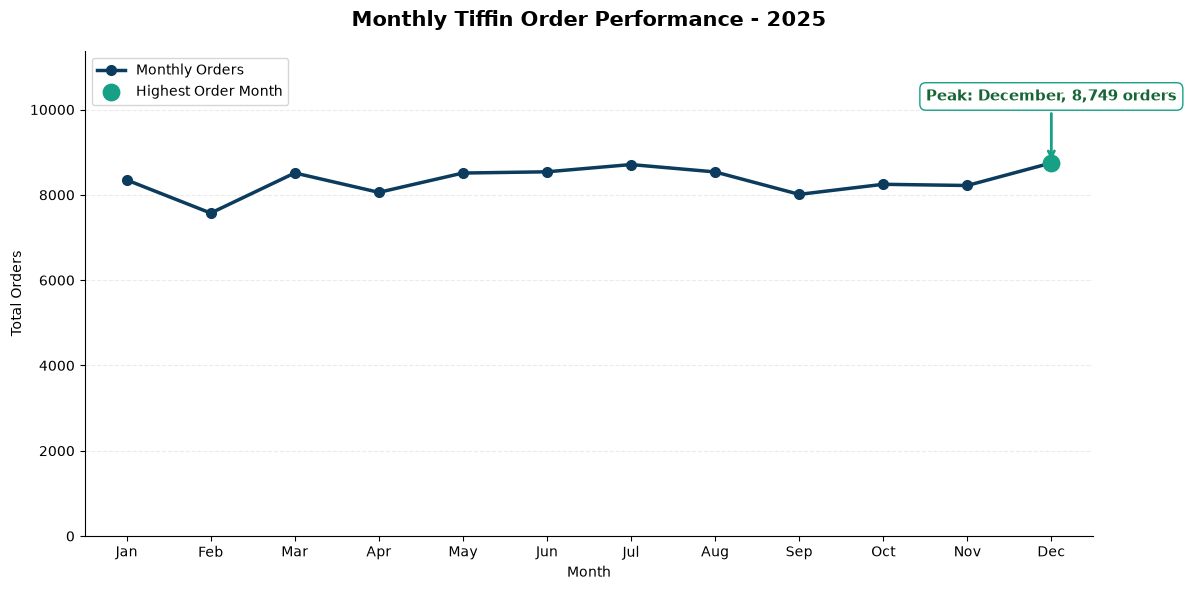

TIFFIN SERVICE - MONTHLY PERFORMANCE
---------------------------------------------
Highest Order Month: December
Orders in Peak Month: 8,749
Total Months Analysed: 12

Session 10 - Task 1 completed successfully!


In [1]:

# MATPLOTLIB SESSION 10 - TASK 1
# Monthly Tiffin Orders - Peak Month Annotation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the existing tiffin dataset
file_path = Path("tiffin_daily.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "tiffin_daily.csv not found. "
        "Place the file in the notebook working folder."
    )

df = pd.read_csv(file_path, parse_dates=["date"])

# Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# Calculate total daily orders
df["total_orders"] = (
    df["veg"] +
    df["jain"] +
    df["diet"]
)

# Calculate monthly total orders
monthly_orders = (
    df.set_index("date")["total_orders"]
    .resample("MS")
    .sum()
)

# Find the highest month dynamically
peak_date = monthly_orders.idxmax()
peak_orders = monthly_orders.loc[peak_date]
peak_month = peak_date.strftime("%B")

# Prepare chart data
months = np.arange(1, len(monthly_orders) + 1)
month_labels = monthly_orders.index.strftime("%b")

peak_position = monthly_orders.index.get_loc(peak_date) + 1

# Create professional line chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    months,
    monthly_orders.values,
    color="#0B3C5D",
    linewidth=2.5,
    marker="o",
    markersize=7,
    label="Monthly Orders"
)

# Highlight peak month
ax.scatter(
    peak_position,
    peak_orders,
    color="#16A085",
    s=140,
    zorder=5,
    label="Highest Order Month"
)

# Add arrow annotation
ax.annotate(
    f"Peak: {peak_month}, {peak_orders:,} orders",
    xy=(peak_position, peak_orders),
    xytext=(0, 45),
    textcoords="offset points",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#166534",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A085",
        linewidth=2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#16A085"
    )
)

# Chart formatting
ax.set_title(
    "Monthly Tiffin Order Performance - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Total Orders")

ax.set_xticks(months)
ax.set_xticklabels(month_labels)

ax.set_xlim(0.5, 12.5)
ax.set_ylim(0, monthly_orders.max() * 1.3)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper left")

fig.tight_layout()

# Task 1: Display chart
# Task 2 will add the summary text box and save the PNG.
plt.show()

# Print peak month summary
print("TIFFIN SERVICE - MONTHLY PERFORMANCE")
print("-" * 45)
print(f"Highest Order Month: {peak_month}")
print(f"Orders in Peak Month: {peak_orders:,}")
print(f"Total Months Analysed: {len(monthly_orders)}")
print("\nSession 10 - Task 1 completed successfully!")


Task 2: Add a Summary Text Box

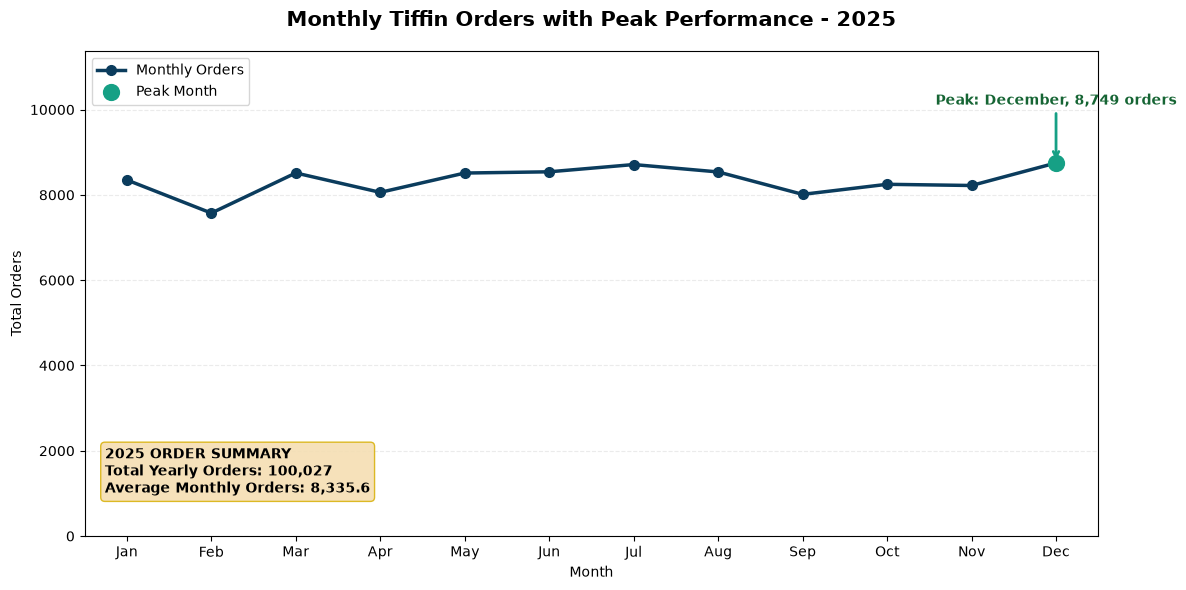

TIFFIN SERVICE - 2025 PERFORMANCE
---------------------------------------------
Total Yearly Orders: 100,027
Average Monthly Orders: 8,335.58
Peak Month: December
Peak Month Orders: 8,749

Chart saved: tiffin_peak_arrow.png
Session 10 - Task 2 completed successfully!


In [2]:

# MATPLOTLIB SESSION 10 - TASK 2
# Peak Month Annotation with Business Summary Box

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load daily tiffin orders
df = pd.read_csv(
    "tiffin_daily.csv",
    parse_dates=["date"]
)

# Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# Calculate daily total orders
df["total_orders"] = df[
    ["veg", "jain", "diet"]
].sum(axis=1)

# Aggregate daily orders into monthly totals
monthly_orders = (
    df.set_index("date")["total_orders"]
    .resample("MS")
    .sum()
)

# Calculate business KPIs
yearly_total = int(monthly_orders.sum())
average_monthly = monthly_orders.mean()

# Identify the highest-order month
peak_date = monthly_orders.idxmax()
peak_orders = int(monthly_orders.loc[peak_date])
peak_month = peak_date.strftime("%B")

# Prepare month positions
months = np.arange(1, len(monthly_orders) + 1)
month_labels = monthly_orders.index.strftime("%b")
peak_position = monthly_orders.index.get_loc(peak_date) + 1

# Create professional chart
plt.figure(figsize=(12, 6))

# Monthly orders line
plt.plot(
    months,
    monthly_orders.values,
    color="#0B3C5D",
    linewidth=2.5,
    marker="o",
    markersize=7,
    label="Monthly Orders"
)

# Highlight peak month
plt.scatter(
    peak_position,
    peak_orders,
    color="#16A085",
    s=130,
    zorder=5,
    label="Peak Month"
)

# Add arrow annotation
plt.annotate(
    f"Peak: {peak_month}, {peak_orders:,} orders",
    xy=(peak_position, peak_orders),
    xytext=(0, 42),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#166534",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A085",
        linewidth=2
    )
)

# Prepare summary text from actual data
summary_text = (
    "2025 ORDER SUMMARY\n"
    f"Total Yearly Orders: {yearly_total:,}\n"
    f"Average Monthly Orders: {average_monthly:,.1f}"
)

# Add summary text box in the bottom-left
plt.text(
    0.02,
    0.08,
    summary_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    fontweight="bold",
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round",
        facecolor="wheat",
        edgecolor="#D9B310",
        alpha=0.9
    )
)

# Chart formatting
plt.title(
    "Monthly Tiffin Orders with Peak Performance - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Month")
plt.ylabel("Total Orders")

plt.xticks(months, month_labels)
plt.xlim(0.5, 12.5)
plt.ylim(0, monthly_orders.max() * 1.3)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend(loc="upper left")

plt.tight_layout()

# Save BEFORE displaying
plt.savefig(
    "tiffin_peak_arrow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print business summary
print("TIFFIN SERVICE - 2025 PERFORMANCE")
print("-" * 45)
print(f"Total Yearly Orders: {yearly_total:,}")
print(f"Average Monthly Orders: {average_monthly:,.2f}")
print(f"Peak Month: {peak_month}")
print(f"Peak Month Orders: {peak_orders:,}")

print("\nChart saved: tiffin_peak_arrow.png")
print("Session 10 - Task 2 completed successfully!")


Task 3: Stacked Bar Chart with Legend Below

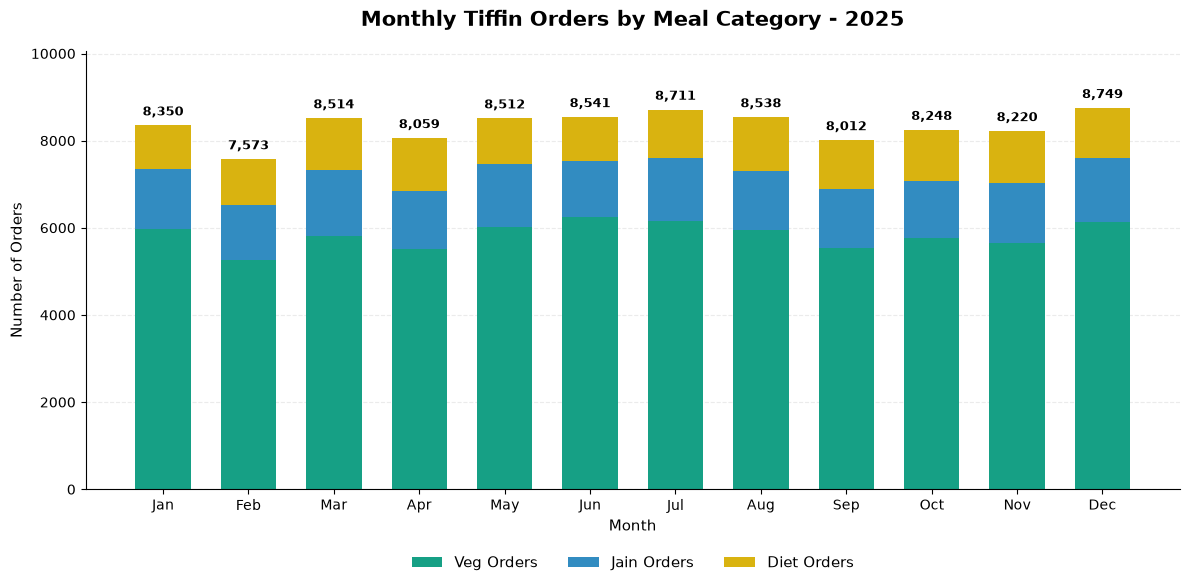

MONTHLY TIFFIN ORDER PERFORMANCE
---------------------------------------------
             veg  jain  diet  total_orders
date                                      
2025-01-01  5973  1365  1012          8350
2025-02-01  5258  1273  1042          7573
2025-03-01  5811  1505  1198          8514
2025-04-01  5522  1327  1210          8059
2025-05-01  6023  1449  1040          8512
2025-06-01  6254  1279  1008          8541
2025-07-01  6162  1446  1103          8711
2025-08-01  5961  1346  1231          8538
2025-09-01  5529  1362  1121          8012
2025-10-01  5777  1303  1168          8248
2025-11-01  5656  1362  1202          8220
2025-12-01  6142  1459  1148          8749

Annual Orders by Category:
veg     70068
jain    16476
diet    13483

Total Annual Orders: 100027

SESSION 10 - TASK 3 COMPLETED
Saved: tiffin_legend_below.png
File Size: 136.6 KB


In [3]:

# MATPLOTLIB SESSION 10 - TASK 3
# Monthly Tiffin Orders with Legend Below Chart

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load the existing business dataset
file_path = Path("tiffin_daily.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "tiffin_daily.csv not found. "
        "Check your VS Code working directory."
    )

df = pd.read_csv(file_path, parse_dates=["date"])

# 2. Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# 3. Prepare monthly totals using resampling
monthly_orders = (
    df.set_index("date")[["veg", "jain", "diet"]]
    .resample("MS")
    .sum()
)

# 4. Prepare plotting data
months = monthly_orders.index.strftime("%b")

veg_orders = monthly_orders["veg"].to_numpy()
jain_orders = monthly_orders["jain"].to_numpy()
diet_orders = monthly_orders["diet"].to_numpy()

total_orders = veg_orders + jain_orders + diet_orders

# 5. Create the stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))

# Bottom layer: Veg
ax.bar(
    months,
    veg_orders,
    width=0.65,
    color="#16A085",
    label="Veg Orders"
)

# Middle layer: Jain
ax.bar(
    months,
    jain_orders,
    bottom=veg_orders,
    width=0.65,
    color="#328CC1",
    label="Jain Orders"
)

# Top layer: Diet
ax.bar(
    months,
    diet_orders,
    bottom=veg_orders + jain_orders,
    width=0.65,
    color="#D9B310",
    label="Diet Orders"
)

# 6. Display total orders above each bar
for index, total in enumerate(total_orders):
    ax.annotate(
        f"{total:,}",
        xy=(index, total),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# 7. Add professional formatting
ax.set_title(
    "Monthly Tiffin Orders by Meal Category - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Number of Orders", fontsize=11)

ax.set_ylim(0, total_orders.max() * 1.15)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# 8. Position legend BELOW the chart
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=11
)

# 9. Adjust layout
fig.tight_layout()

# 10. Save BEFORE displaying
output_file = Path("tiffin_legend_below.png")

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 11. Print business summary
print("MONTHLY TIFFIN ORDER PERFORMANCE")
print("-" * 45)

summary = monthly_orders.copy()
summary["total_orders"] = total_orders

print(summary.to_string())

print("\nAnnual Orders by Category:")
print(
    monthly_orders.sum().to_string()
)

print("\nTotal Annual Orders:", total_orders.sum())

print("\nSESSION 10 - TASK 3 COMPLETED")
print(f"Saved: {output_file.name}")
print(f"File Size: {output_file.stat().st_size / 1024:.1f} KB")


Task 4: Professional Tiffin Sales Story Chart

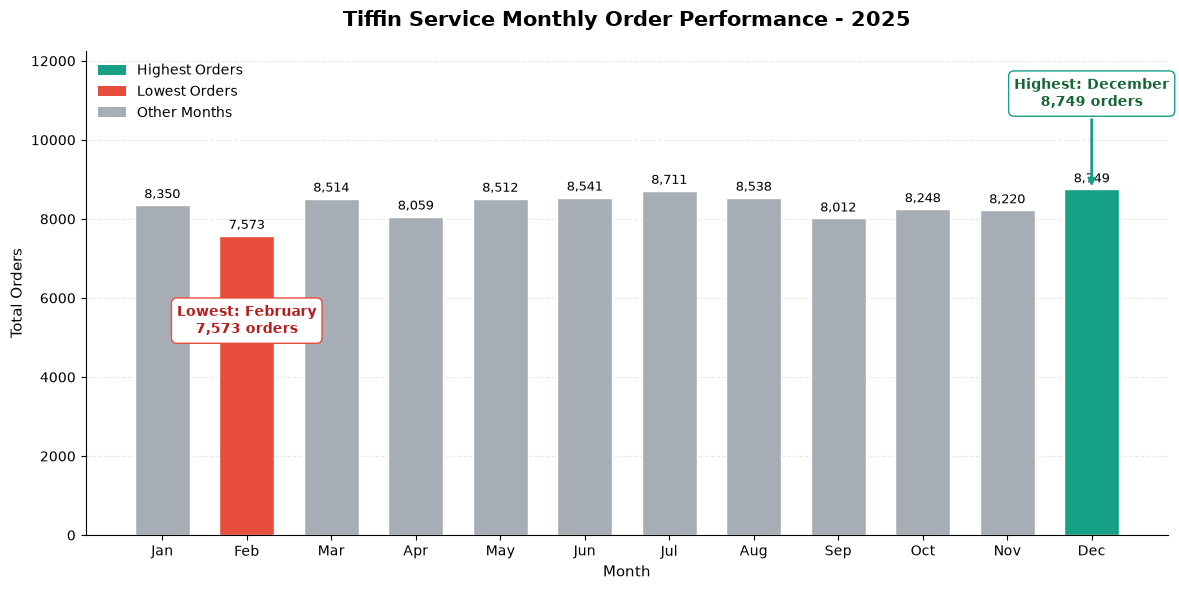

TIFFIN SERVICE - MONTHLY PERFORMANCE STORY
--------------------------------------------------
Highest Order Month: December (8,749 orders)
Lowest Order Month: February (7,573 orders)
Difference Between Highest and Lowest: 1,176 orders
Total Annual Orders: 100,027

Saved: tiffin_story_chart.png
File Size: 170.5 KB

SESSION 10 - TASK 4 COMPLETED SUCCESSFULLY!


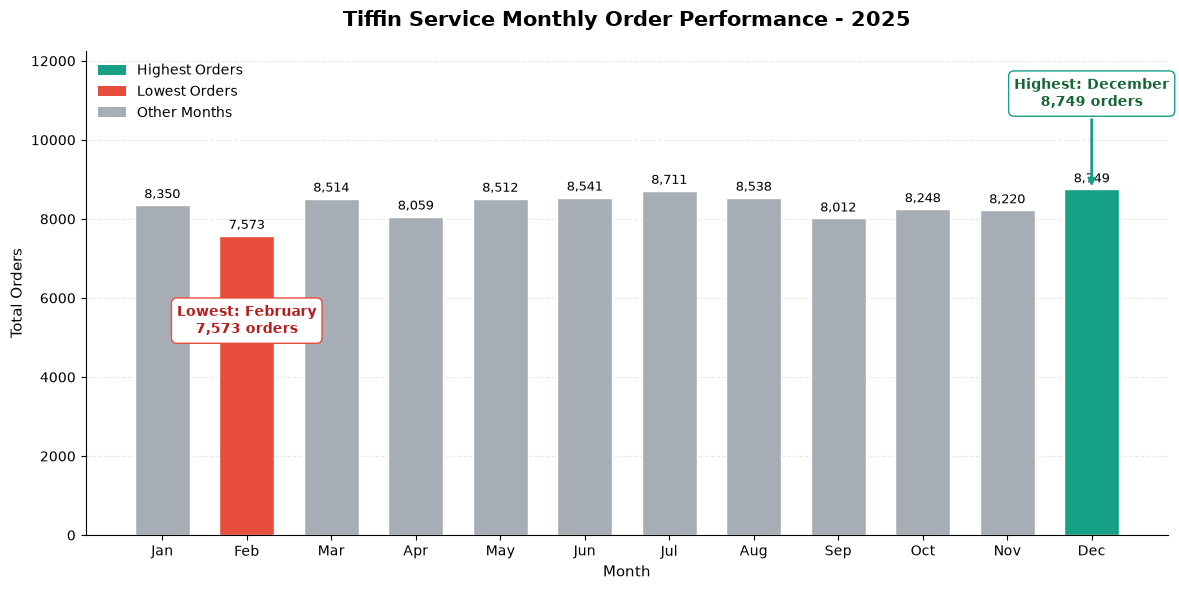

TIFFIN SERVICE - MONTHLY PERFORMANCE STORY
--------------------------------------------------
Highest Order Month: December (8,749 orders)
Lowest Order Month: February (7,573 orders)
Difference Between Highest and Lowest: 1,176 orders
Total Annual Orders: 100,027

Saved: tiffin_story_chart.png
File Size: 170.5 KB

SESSION 10 - TASK 4 COMPLETED SUCCESSFULLY!


In [4]:

# MATPLOTLIB SESSION 10 - TASK 4
# Monthly Tiffin Orders - Performance Story Chart

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# Load the existing tiffin orders dataset
data_path = Path("tiffin_daily.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "tiffin_daily.csv not found. "
        "Check the VS Code working directory."
    )

df = pd.read_csv(
    data_path,
    parse_dates=["date"]
)

# Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )

if df["date"].isna().any():
    raise ValueError("Invalid dates found in dataset.")

# Calculate total orders per day
df["total_orders"] = df[
    ["veg", "jain", "diet"]
].sum(axis=1)

# Aggregate daily orders into monthly totals
monthly_orders = (
    df.set_index("date")["total_orders"]
    .resample("MS")
    .sum()
)

# Identify best and worst performing months
highest_month = monthly_orders.idxmax()
lowest_month = monthly_orders.idxmin()

highest_orders = int(monthly_orders.loc[highest_month])
lowest_orders = int(monthly_orders.loc[lowest_month])

# Prepare chart values
months = np.arange(len(monthly_orders))
month_labels = monthly_orders.index.strftime("%b")

# Assign colors dynamically
bar_colors = []

for month in monthly_orders.index:
    if month == highest_month:
        bar_colors.append("#16A085")  # Green
    elif month == lowest_month:
        bar_colors.append("#E74C3C")  # Red
    else:
        bar_colors.append("#A7ADB4")  # Gray

# Create professional storytelling chart
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    months,
    monthly_orders.values,
    color=bar_colors,
    width=0.65,
    edgecolor="white",
    linewidth=1
)

# Add order totals above each bar
for bar in bars:
    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 100,
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Find chart positions of highest and lowest months
highest_position = monthly_orders.index.get_loc(highest_month)
lowest_position = monthly_orders.index.get_loc(lowest_month)

# Highlight highest month with arrow
ax.annotate(
    f"Highest: {highest_month.strftime('%B')}\n"
    f"{highest_orders:,} orders",
    xy=(highest_position, highest_orders),
    xytext=(0, 60),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#166534",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A085",
        linewidth=2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#16A085"
    )
)

# Highlight lowest month with arrow
ax.annotate(
    f"Lowest: {lowest_month.strftime('%B')}\n"
    f"{lowest_orders:,} orders",
    xy=(lowest_position, lowest_orders),
    xytext=(0, -70),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#B91C1C",
    arrowprops=dict(
        arrowstyle="->",
        color="#E74C3C",
        linewidth=2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#E74C3C"
    )
)

# Chart title and labels
ax.set_title(
    "Tiffin Service Monthly Order Performance - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Total Orders", fontsize=11)

ax.set_xticks(months)
ax.set_xticklabels(month_labels)

ax.set_ylim(0, monthly_orders.max() * 1.4)

# Add light gridlines
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Create meaningful legend
legend_items = [
    Patch(facecolor="#16A085", label="Highest Orders"),
    Patch(facecolor="#E74C3C", label="Lowest Orders"),
    Patch(facecolor="#A7ADB4", label="Other Months")
]

ax.legend(
    handles=legend_items,
    loc="upper left",
    frameon=False
)

fig.tight_layout()

# Save BEFORE displaying
output_file = Path("tiffin_story_chart.png")

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print business performance summary
print("TIFFIN SERVICE - MONTHLY PERFORMANCE STORY")
print("-" * 50)

print(
    f"Highest Order Month: "
    f"{highest_month.strftime('%B')} "
    f"({highest_orders:,} orders)"
)

print(
    f"Lowest Order Month: "
    f"{lowest_month.strftime('%B')} "
    f"({lowest_orders:,} orders)"
)

print(
    f"Difference Between Highest and Lowest: "
    f"{highest_orders - lowest_orders:,} orders"
)

print(
    f"Total Annual Orders: "
    f"{monthly_orders.sum():,}"
)

print("\nSaved:", output_file.name)
print(
    "File Size:",
    f"{output_file.stat().st_size / 1024:.1f} KB"
)

print("\nSESSION 10 - TASK 4 COMPLETED SUCCESSFULLY!")

# MATPLOTLIB SESSION 10 - TASK 4
# Monthly Tiffin Orders - Performance Story Chart

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# Load the existing tiffin orders dataset
data_path = Path("tiffin_daily.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "tiffin_daily.csv not found. "
        "Check the VS Code working directory."
    )

df = pd.read_csv(
    data_path,
    parse_dates=["date"]
)

# Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )

if df["date"].isna().any():
    raise ValueError("Invalid dates found in dataset.")

# Calculate total orders per day
df["total_orders"] = df[
    ["veg", "jain", "diet"]
].sum(axis=1)

# Aggregate daily orders into monthly totals
monthly_orders = (
    df.set_index("date")["total_orders"]
    .resample("MS")
    .sum()
)

# Identify best and worst performing months
highest_month = monthly_orders.idxmax()
lowest_month = monthly_orders.idxmin()

highest_orders = int(monthly_orders.loc[highest_month])
lowest_orders = int(monthly_orders.loc[lowest_month])

# Prepare chart values
months = np.arange(len(monthly_orders))
month_labels = monthly_orders.index.strftime("%b")

# Assign colors dynamically
bar_colors = []

for month in monthly_orders.index:
    if month == highest_month:
        bar_colors.append("#16A085")  # Green
    elif month == lowest_month:
        bar_colors.append("#E74C3C")  # Red
    else:
        bar_colors.append("#A7ADB4")  # Gray

# Create professional storytelling chart
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    months,
    monthly_orders.values,
    color=bar_colors,
    width=0.65,
    edgecolor="white",
    linewidth=1
)

# Add order totals above each bar
for bar in bars:
    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 100,
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Find chart positions of highest and lowest months
highest_position = monthly_orders.index.get_loc(highest_month)
lowest_position = monthly_orders.index.get_loc(lowest_month)

# Highlight highest month with arrow
ax.annotate(
    f"Highest: {highest_month.strftime('%B')}\n"
    f"{highest_orders:,} orders",
    xy=(highest_position, highest_orders),
    xytext=(0, 60),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#166534",
    arrowprops=dict(
        arrowstyle="->",
        color="#16A085",
        linewidth=2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#16A085"
    )
)

# Highlight lowest month with arrow
ax.annotate(
    f"Lowest: {lowest_month.strftime('%B')}\n"
    f"{lowest_orders:,} orders",
    xy=(lowest_position, lowest_orders),
    xytext=(0, -70),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#B91C1C",
    arrowprops=dict(
        arrowstyle="->",
        color="#E74C3C",
        linewidth=2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#E74C3C"
    )
)

# Chart title and labels
ax.set_title(
    "Tiffin Service Monthly Order Performance - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Total Orders", fontsize=11)

ax.set_xticks(months)
ax.set_xticklabels(month_labels)

ax.set_ylim(0, monthly_orders.max() * 1.4)

# Add light gridlines
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Create meaningful legend
legend_items = [
    Patch(facecolor="#16A085", label="Highest Orders"),
    Patch(facecolor="#E74C3C", label="Lowest Orders"),
    Patch(facecolor="#A7ADB4", label="Other Months")
]

ax.legend(
    handles=legend_items,
    loc="upper left",
    frameon=False
)

fig.tight_layout()

# Save BEFORE displaying
output_file = Path("tiffin_story_chart.png")

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print business performance summary
print("TIFFIN SERVICE - MONTHLY PERFORMANCE STORY")
print("-" * 50)

print(
    f"Highest Order Month: "
    f"{highest_month.strftime('%B')} "
    f"({highest_orders:,} orders)"
)

print(
    f"Lowest Order Month: "
    f"{lowest_month.strftime('%B')} "
    f"({lowest_orders:,} orders)"
)

print(
    f"Difference Between Highest and Lowest: "
    f"{highest_orders - lowest_orders:,} orders"
)

print(
    f"Total Annual Orders: "
    f"{monthly_orders.sum():,}"
)

print("\nSaved:", output_file.name)
print(
    "File Size:",
    f"{output_file.stat().st_size / 1024:.1f} KB"
)

print("\nSESSION 10 - TASK 4 COMPLETED SUCCESSFULLY!")
